(why-pseudobulk)=
# Why pseudobulk

A study of 12 donors that measures 300 cells of a cell type in each donor has 12
replicates of that cell type, not 3,600. Cells of one donor share its genotype, its
environment and the handling of its sample, so they resemble each other more than they
resemble the cells of other donors. A test that treats the cells as replicates measures
a difference against a standard error that shrinks with every cell sampled, and calls
differences that other donors do not share [@squair2021; @zimmerman2021]. Pooling the
cells of each sample and cell type into one profile, a pseudobulk profile, makes the
sample the unit of every test: a difference is then measured against the variation
between donors, with the methods that bulk RNA-seq developed for it.

This page shows the problem on a comparison in which nothing differs, then what
benchmarks and studies of replication found.

## A comparison in which nothing differs

The control samples of the simulated PBMC study come from 12 donors who were treated
alike ([Datasets](reference/datasets.md)). Split at random into two groups of six,
they differ in no gene, beyond the small shift that the simulation gives every gene of
each donor, in all of the donor's cells, as real donors differ. Every gene of a cell
type is tested between the two groups in two ways:

- **Cells as replicates:** Welch's t-test on the log-normalized values of the cells,
  the test that scanpy's `rank_genes_groups` runs by default [@wolf2018]. The cube
  holds what it needs: the cells of each group's samples, pooled by
  {api}`Cube.collapse_samples`, give the mean and the variance of the cells' values
  ({api}`Cube.mean`, {api}`Cube.variance`).
- **Samples as replicates:** {api}`limma_voom` on the pseudobulk profiles of the 12
  samples.

CytePool 0.1.dev70+g194507939
group A: D01, D05, D06, D08, D09, D12
group B: D02, D03, D04, D07, D10, D11


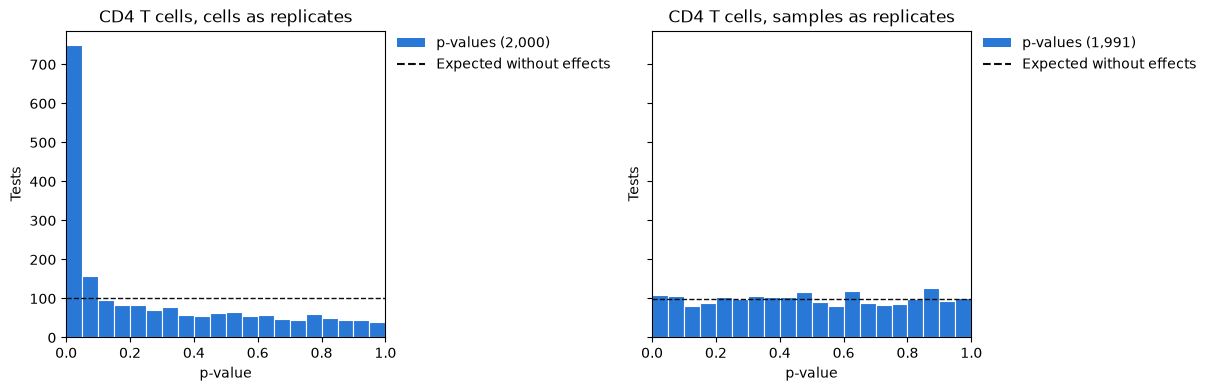

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import cytepool
from cytepool import Design, limma_voom, read_cube
from cytepool.plotting import plot_p_values
from cytepool.stats.distributions import t_sf
from cytepool.stats.multiple_testing import adjust_p_values

cube = read_cube("simulated_pbmc.cube.zarr")
controls = cube.select(samples=cube.samples["condition"] == "ctrl")
donors = controls.samples["donor"]
in_a = np.isin(donors, np.random.default_rng(1).permutation(donors)[:6])
print(f"CytePool {cytepool.__version__}")
print("group A:", ", ".join(donors[in_a]))
print("group B:", ", ".join(donors[~in_a]))


def pooled_cells(cube, group, samples):
    # The cells of some samples of one cell type, pooled: how many, and the mean and
    # variance of every gene's log-normalized values.
    pooled = cube.select(samples=samples, groups=group).collapse_samples()
    return pooled.n_cells[0, 0], pooled.mean(group)[0], pooled.variance(group)[0]


def test_of_cells(cube, group, in_a):
    # Welch's t-test of every gene between the cells of two sets of samples.
    (n_a, mean_a, var_a), (n_b, mean_b, var_b) = (
        pooled_cells(cube, group, samples) for samples in (in_a, ~in_a)
    )
    se2_a, se2_b = var_a / n_a, var_b / n_b
    t = (mean_a - mean_b) / np.sqrt(se2_a + se2_b)
    df = (se2_a + se2_b) ** 2 / (se2_a**2 / (n_a - 1) + se2_b**2 / (n_b - 1))
    return 2 * t_sf(np.abs(t), df)


design = Design(
    controls.samples.with_columns(group=np.where(in_a, "A", "B")),
    "~ group",
    levels={"group": ["A", "B"]},
    contrasts={"B_vs_A": "groupB"},
)
of_samples = limma_voom(controls, design)

cd4 = "CD4 T cells"
figure, (left, right) = plt.subplots(
    1, 2, figsize=(12, 3.8), layout="constrained", sharey=True
)
plot_p_values(test_of_cells(controls, cd4, in_a), ax=left)
left.set_title("CD4 T cells, cells as replicates")
plot_p_values(of_samples.table(cd4, "B_vs_A"), ax=right)
right.set_title("CD4 T cells, samples as replicates")
plt.show()

Without a difference, p-values are spread evenly between 0 and 1, and each bin of the
histogram holds about as many genes as the dashed line. The test of the samples gives
that. The test of the cells gives p-values below 0.05 to more than a third of the
genes, every one of them a false positive.

## More cells, more false discoveries

The same two tests in every cell type, with the genes each calls at a false discovery
rate of 5% ({api}`adjust_p_values`, as Benjamini and Hochberg's method adjusts them):

In [2]:
print(f"{'cell type':<16}{'cells':>7}{'calls, cells':>14}{'calls, samples':>16}")
for group, n in zip(controls.groups["group_id"], controls.n_cells.sum(axis=0)):
    by_cells = np.sum(adjust_p_values(test_of_cells(controls, group, in_a)) < 0.05)
    by_samples = np.sum(of_samples.table(group, "B_vs_A")["adjusted_p_value"] < 0.05)
    print(f"{group:<16}{n:>7,}{by_cells:>14,}{by_samples:>16,}")

cell type         cells  calls, cells  calls, samples
B cells           1,161           203               0
CD4 T cells       3,097           553               0
CD8 T cells       1,412           288               0
NK cells          1,114           153               0
Monocytes         2,533           442               0
Dendritic cells     191             6               0


Every call is false. The test of the samples makes none, and the test of the cells
makes hundreds in every cell type with many cells, more the more cells it is given: the
dendritic cells, about 16 in each sample, have the fewest calls.

## Why the test of the cells fails

Take the gene of the CD4 T cells that the test of the cells finds most significant,
and draw the mean of every donor's cells, and the mean of each group's cells with the
95% confidence interval that the test of the cells gives it:

gene_1915: p-value 4e-27 testing cells, 0.02 testing samples


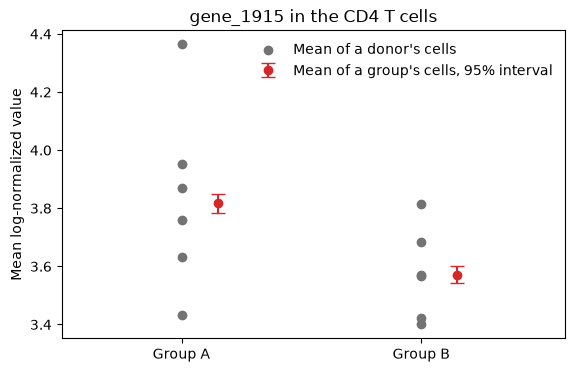

In [3]:
p_cells = test_of_cells(controls, cd4, in_a)
gene = int(np.argmin(p_cells))
name = controls.features["feature_id"][gene]
p_samples = of_samples.table(cd4, "B_vs_A").filter(feature_id=name)["p_value"][0]
print(
    f"{name}: p-value {p_cells[gene]:.0e} testing cells, {p_samples:.2f} testing samples"
)

pooled = [pooled_cells(controls, cd4, samples) for samples in (in_a, ~in_a)]
figure, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(
    np.where(in_a, 0, 1),
    controls.mean(cd4)[:, gene],
    color="0.45",
    label="Mean of a donor's cells",
)
ax.errorbar(
    [0.15, 1.15],
    [mean[gene] for _, mean, _ in pooled],
    yerr=[1.96 * np.sqrt(variance[gene] / n) for n, _, variance in pooled],
    fmt="o",
    color="tab:red",
    capsize=5,
    label="Mean of a group's cells, 95% interval",
)
ax.set_xticks([0, 1], ["Group A", "Group B"])
ax.set_xlim(-0.5, 1.6)
ax.set_ylabel("Mean log-normalized value")
ax.set_title(f"{name} in the CD4 T cells")
ax.legend(frameon=False)
plt.show()

The donors of one group differ from each other more than the two groups differ. The
test of the cells measures the difference against the precision of each group's mean
over some 1,500 cells, the red intervals: that precision says how well these 12 donors
were measured, not how another 12 donors would differ. The test of the samples measures
the same difference against the spread of the donors, and its p-value of 0.02 is no
discovery among 2,000 genes.

## What benchmarks found

Studies that compared methods on data whose truth was known report:

- @squair2021 compared differential expression methods on eighteen datasets with
  matched bulk RNA-seq. Methods that ignore the variation between biological replicates
  were biased and prone to false discoveries, and the most widely used methods could
  discover hundreds of differentially expressed genes in the absence of biological
  differences.
- @zimmerman2021 showed that cells of one individual are not statistically independent
  and that ignoring it leads to highly inflated type 1 error rates. They proposed
  mixed models with a random effect for the individual, and found pseudobulk methods
  conservative and underpowered in comparison.
- @murphy2022 reran that benchmark with the Matthews correlation coefficient, a measure
  that balances false positives and false negatives, and found that pseudobulk methods
  performed best.
- @junttila2022 compared 18 methods for differential states between conditions in data
  of several subjects: pseudobulk methods performed generally best, and methods that
  treat cells as independent were more sensitive but gave many false positives.
- @crowell2020 surveyed cell-level mixed models and methods on pseudobulk data for
  differential state analysis, with a simulation of single-cell data of several
  samples and conditions.
- @lun2017 showed that ignoring plate effects loses control of the type 1 error, and
  that summing the counts of the cells of each plate restores it, without losing power
  in their simulations.
- @hafner2025 found that methods built for single cells offered no advantage over
  pseudobulk DESeq2 on individual datasets in nested designs, and suggested dream as a
  compromise at atlas scale.
- @nguyen2023 benchmarked 46 workflows for data from several batches: batch-corrected
  data rarely improved the analysis of sparse data, while modelling the batch as a
  covariate helped where batch effects were large.
- @heumos2023 summarized independent benchmarks into best-practice workflows for
  single-cell analysis.

## Results that replicate

Results that rest on cells as replicates include many that a test of donors does not
find, and even results that compare donors replicate less often than their p-values
suggest:

- @murphy2023 re-analysed the first single-nucleus study of Alzheimer's disease. A
  pseudobulk analysis of the authors' processed data found 26 differentially expressed
  genes at a false discovery rate of 0.05, 549 times fewer than the 14,274 of the
  analysis of cells.
- @nakatsuka2025 found that over 85% of the Alzheimer's disease genes called in one of
  17 datasets, with pseudobulk tests, failed to reproduce in any of the 16 others, and
  that a meta-analysis of ranks across datasets found genes that predicted disease
  better.
- @garg2021 re-analysed COVID-19 single-cell studies in a standard way and confirmed 8
  of 20 published results across datasets.

Pooling the cells removes the false positives of pseudoreplication. Small studies and
differences between studies remain, which the chapters on several studies take up
([Why findings fail to
replicate](statistics/aligning_studies.md#why-findings-fail-to-replicate)).

## Choices

- **Pool, then test.** {api}`from_cells` pools the cells of every sample and cell type
  ([Pool cells into pseudobulk profiles](guides/pool_cells.ipynb)), and
  {api}`limma_voom` tests the profiles of every cell type ([Genes that change in each
  cell type](guides/genes_per_cell_type.ipynb)).
- **Profiles of few cells.** A profile of a handful of cells is noisy: `min_cells` (10
  by default) leaves such profiles out of a fit ([Samples with few cells or
  counts](statistics/normalization_and_filtering.md#samples-with-few-cells)), and
  `prior_weights="n_cells"` instead weights every profile by its number of cells
  ([Prior weights from the number of
  cells](statistics/limma_voom.md#prior-weights-from-cells)).
- **Several samples of a donor.** They are not independent either: pair them in the
  design, `~ donor + condition`, or give the donor a random effect with
  {api}`dream_voom` ([A fixed or a random donor
  effect](statistics/mixed_models.md#fixed-or-random-donor), and [Repeated measures and
  donors](guides/repeated_measures.ipynb) on data).
- **Models of the cells.** Generalized linear mixed models with a random effect for
  each individual model the cells themselves [@zimmerman2021]; CytePool does not fit
  them.
- **Descriptions of the cells.** What fraction of a cell type's cells express a gene,
  and how much, describe the cells and need no test: the dot plot draws them from the
  cube ([Pool cells into pseudobulk profiles](guides/pool_cells.ipynb)).